<a href="https://colab.research.google.com/github/sofiamartinlp-wq/proyecto-co2/blob/main/proyecto_co2_colombia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")

df = pd.read_csv("annual-share-of-co2-emissions.csv")
df.columns = ["pais", "codigo", "anio", "porcentaje"]
df.info()
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'annual-share-of-co2-emissions.csv'

In [2]:
!ls

annual-share-of-co2-emissions.zip  sample_data


In [4]:
!unzip annual-share-of-co2-emissions.zip

Archive:  annual-share-of-co2-emissions.zip
replace annual-share-of-co2-emissions.metadata.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")

df = pd.read_csv("annual-share-of-co2-emissions.csv")
df.columns = ["pais", "codigo", "anio", "porcentaje"]
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28386 entries, 0 to 28385
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   pais        28386 non-null  object 
 1   codigo      26889 non-null  object 
 2   anio        28386 non-null  int64  
 3   porcentaje  28386 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 887.2+ KB


,pais,codigo,anio,porcentaje
0,Afghanistan,AFG,1949,0.000281
1,Afghanistan,AFG,1950,0.001361
2,Afghanistan,AFG,1951,0.001379
3,Afghanistan,AFG,1952,0.001361
4,Afghanistan,AFG,1953,0.001490


In [6]:
print("Duplicados:", df.duplicated().sum())
print(df.isna().sum())
print("Rango de años:", df["anio"].min(), "-", df["anio"].max())

Duplicados: 0
pais             0
codigo        1497
anio             0
porcentaje       0
dtype: int64
Rango de años: 1750 - 2025


In [7]:
agregados = df[df["codigo"].isna() | df["codigo"].str.startswith("OWID", na=False)]
print(sorted(agregados["pais"].unique()))

paises = df[df["codigo"].notna() & ~df["codigo"].str.startswith("OWID", na=False)].copy()
print("Países:", paises["pais"].nunique())

['Africa', 'Asia', 'Asia (excl. China and India)', 'Europe', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)', 'European Union (27)', 'European Union (28)', 'High-income countries', 'International aviation', 'International shipping', 'Kosovo', 'Low-income countries', 'Lower-middle-income countries', 'North America', 'North America (excl. USA)', 'Oceania', 'South America', 'Upper-middle-income countries', 'World']
Países: 220


In [8]:
colombia = paises[(paises["pais"] == "Colombia") & (paises["anio"] >= 1950)].copy()
print(colombia.shape)
colombia.describe()

(76, 4)


,anio,porcentaje
count,76.000000,76.000000
mean,1987.500000,0.220124
std,22.083176,0.039648
min,1950.000000,0.118034
25%,1968.750000,0.197095
50%,1987.500000,0.224864
75%,2006.250000,0.246169
max,2025.000000,0.285797


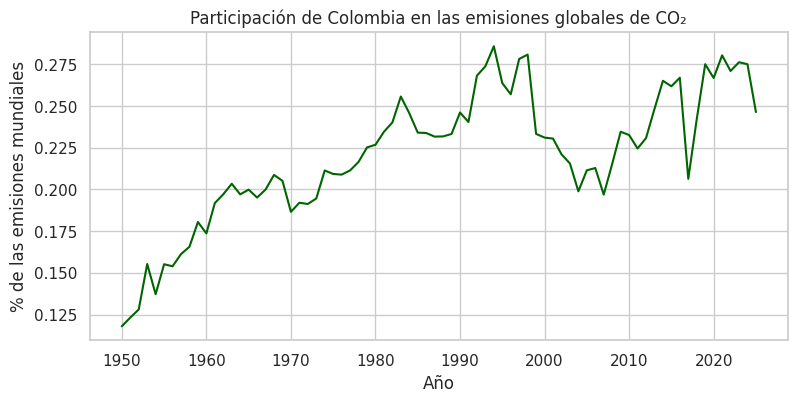

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(colombia["anio"], colombia["porcentaje"], color="darkgreen")
plt.title("Participación de Colombia en las emisiones globales de CO₂")
plt.xlabel("Año")
plt.ylabel("% de las emisiones mundiales")
plt.show()

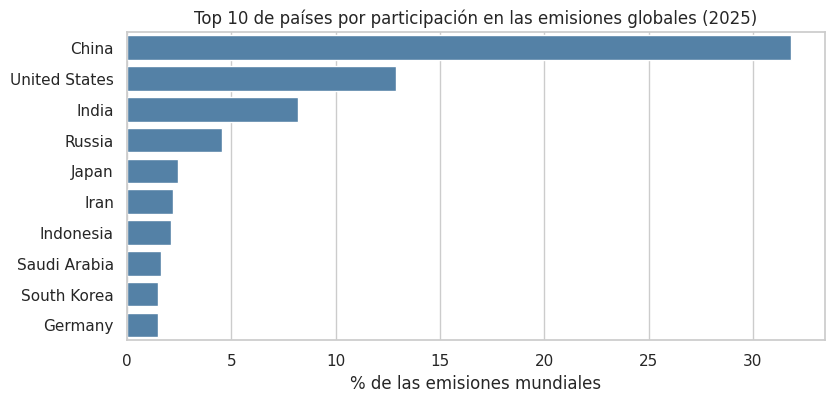

In [10]:
ultimo = paises["anio"].max()
top10 = paises[paises["anio"] == ultimo].nlargest(10, "porcentaje")

plt.figure(figsize=(9, 4))
sns.barplot(data=top10, x="porcentaje", y="pais", color="steelblue")
plt.title(f"Top 10 de países por participación en las emisiones globales ({ultimo})")
plt.xlabel("% de las emisiones mundiales")
plt.ylabel("")
plt.show()

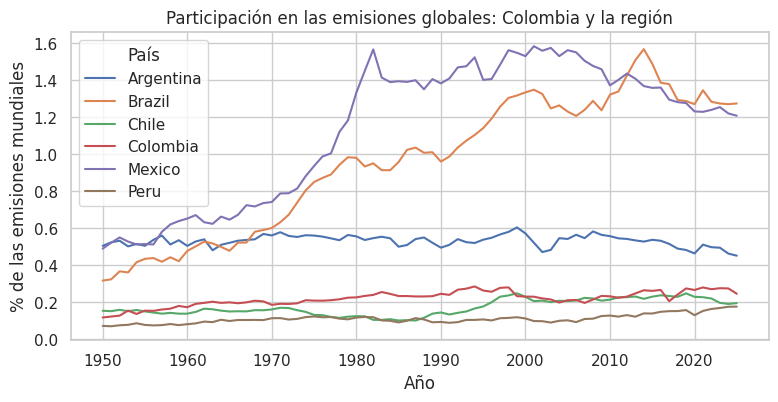

In [11]:
region = ["Colombia", "Brazil", "Mexico", "Argentina", "Chile", "Peru"]
comp = paises[(paises["pais"].isin(region)) & (paises["anio"] >= 1950)]

plt.figure(figsize=(9, 4))
sns.lineplot(data=comp, x="anio", y="porcentaje", hue="pais")
plt.title("Participación en las emisiones globales: Colombia y la región")
plt.xlabel("Año")
plt.ylabel("% de las emisiones mundiales")
plt.legend(title="País")
plt.show()

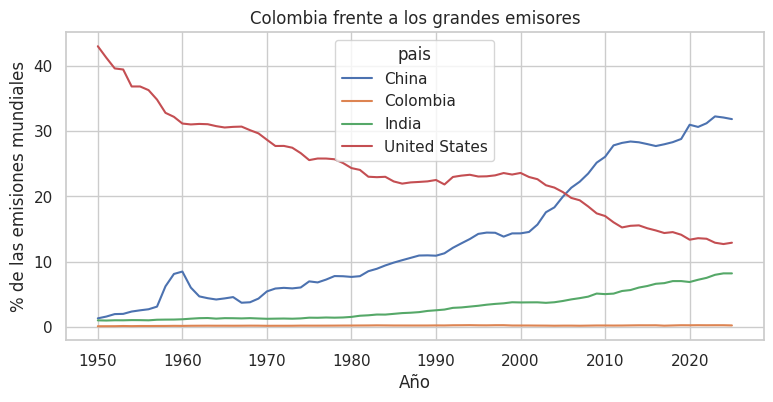

In [12]:
grandes = paises[(paises["pais"].isin(["China", "United States", "India", "Colombia"])) & (paises["anio"] >= 1950)]

plt.figure(figsize=(9, 4))
sns.lineplot(data=grandes, x="anio", y="porcentaje", hue="pais")
plt.title("Colombia frente a los grandes emisores")
plt.xlabel("Año")
plt.ylabel("% de las emisiones mundiales")
plt.show()

In [13]:
X = colombia[["anio"]]
y = colombia["porcentaje"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)
print("R²:", r2_score(y, modelo.predict(X)))

Pendiente: 0.0014033272012303486
Intercepto: -2.5689890638926864
R²: 0.6109357018692363


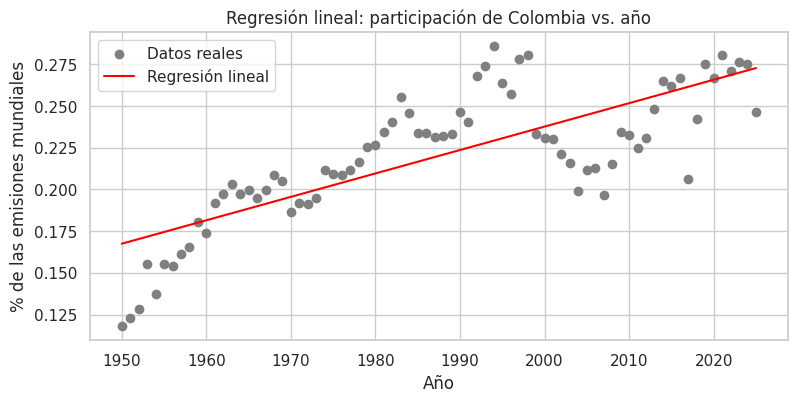

In [14]:
plt.figure(figsize=(9, 4))
plt.scatter(colombia["anio"], colombia["porcentaje"], color="gray", label="Datos reales")
plt.plot(colombia["anio"], modelo.predict(X), color="red", label="Regresión lineal")
plt.title("Regresión lineal: participación de Colombia vs. año")
plt.xlabel("Año")
plt.ylabel("% de las emisiones mundiales")
plt.legend()
plt.show()

In [15]:
corte = int(len(colombia) * 0.8)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

modelo2 = LinearRegression().fit(X_train, y_train)
pred = modelo2.predict(X_test)

print("R² entrenamiento:", r2_score(y_train, modelo2.predict(X_train)))
print("R² prueba:", r2_score(y_test, pred))
print("RMSE prueba:", np.sqrt(mean_squared_error(y_test, pred)))

R² entrenamiento: 0.5620820064690235
R² prueba: -0.5507193670251191
RMSE prueba: 0.026502338111605662


In [16]:
resultados = []
for p in ["Colombia", "Brazil", "Mexico", "Argentina", "Chile", "Peru", "China", "United States", "India"]:
    d = paises[(paises["pais"] == p) & (paises["anio"] >= 1950)]
    m = LinearRegression().fit(d[["anio"]], d["porcentaje"])
    resultados.append({"pais": p, "pendiente": m.coef_[0], "R2": m.score(d[["anio"]], d["porcentaje"])})

pd.DataFrame(resultados).sort_values("pendiente", ascending=False)

,pais,pendiente,R2
6,China,0.417673,0.905603
8,India,0.091757,0.871128
1,Brazil,0.015537,0.911272
2,Mexico,0.013498,0.644456
0,Colombia,0.001403,0.610936
4,Chile,0.001344,0.479772
5,Peru,0.000860,0.600346
3,Argentina,-0.000233,0.028909
7,United States,-0.320309,0.924520


## 5. Interpretación de resultados

### 5.1 Resultados del modelo
Se ajustó una regresión lineal simple para Colombia entre 1950 y 2025, con el año como variable explicativa y el porcentaje de las emisiones globales de CO₂ como variable a explicar. Los resultados fueron:
- Pendiente: 0,0014 puntos porcentuales por año
- R² con todos los datos: 0,61
- R² de entrenamiento (1950-2009): 0,56
- R² de prueba (2010-2025): -0,55
- RMSE de prueba: 0,0265

### 5.2 Interpretación
La pendiente positiva indica que la participación de Colombia en las emisiones mundiales ha aumentado en promedio 0,0014 puntos porcentuales cada año. El R² de 0,61 significa que la recta explica cerca del 61 % de la variación de los datos, un ajuste moderado: capta la tendencia general de subida, pero no todos los cambios. En los datos de prueba, el R² negativo indica que el modelo predice peor que simplemente usar el promedio de esos años, así que no sirve para pronosticar. El RMSE de 0,0265 indica que, en promedio, el modelo se equivoca en unos 0,027 puntos porcentuales, un error importante frente a valores que están entre 0,20 % y 0,28 %.

### 5.3 Comparación entre países
Al aplicar el mismo modelo a otros países, China (+0,418) e India (+0,092) ganan participación de forma marcada, mientras que Estados Unidos (-0,320) la pierde. Colombia (+0,0014) crece muy poco en comparación, al igual que Chile y Perú. Argentina tiene un R² cercano a 0 (0,03), lo que indica que no hay una tendencia lineal y su pendiente no debe interpretarse. Como los porcentajes suman 100 %, lo que gana un país lo pierden otros.

### 5.4 Conexión con el artículo de Our World in Data
El artículo muestra que las emisiones de CO₂ se concentran en pocos países grandes y que el peso de cada uno cambia con el tiempo. Los resultados del modelo reflejan esa idea: China e India aumentan su participación, Estados Unidos la reduce, y Colombia aporta una fracción muy pequeña del total mundial (entre 0,12 % y 0,29 %).

### 5.5 Limitaciones
- Una recta no capta los cambios de ritmo: la participación de Colombia sube hasta los años 90, baja hasta cerca de 2007 y vuelve a subir.
- Hay pocos datos (un valor por año), por lo que el conjunto de prueba es pequeño.
- Los datos muestran participación relativa, no emisiones absolutas: un país puede emitir más y aun así bajar su porcentaje si otros crecen más rápido.
- Correlación no es causalidad: el modelo describe la tendencia, pero no explica por qué cambia.

## 6. Conclusión
La participación de Colombia en las emisiones globales de CO₂ ha aumentado de forma lenta desde 1950, y la regresión lineal describe bien esa tendencia general (R² de 0,61). Sin embargo, el modelo no predice bien los años recientes (R² de prueba negativo), porque la evolución real tiene subidas y bajadas que una recta no recoge. En comparación con China e India, el aporte de Colombia es muy pequeño. La regresión lineal sirve para describir la tendencia histórica, pero no para pronosticar el futuro.